# 🎬 Semana 4 — Taller práctico evaluado: EDA con Netflix
## Caso: ¿Qué nos cuenta el catálogo de Netflix?
**Asignatura:** Inteligencia Artificial · **Duración:** 3 horas (120 minutos de práctica + 60 minutos de exposiciones) · **Modalidad:** guiada · **Calificación:** 50 puntos  
**Estudiante:** Esteban Ruiz · **Paralelo:** A · **Fecha:** 20/10/2026

**Propósito:** aplicar el Análisis Exploratorio de Datos (EDA) para comprender el catálogo de películas y series, detectar problemas de calidad, construir gráficos e interpretar hallazgos. **No se construirá un modelo predictivo.**

**Pregunta investigadora:** ¿Cómo se distribuye el contenido de Netflix según tipo, año, duración, país y clasificación por edades?

**Fuente:** [Netflix Movies and TV Shows — Kaggle (shivamb)](https://www.kaggle.com/datasets/shivamb/netflix-shows). El archivo esperado se llama `netflix_titles.csv`. Los datos son una instantánea histórica del catálogo, **no representan necesariamente el catálogo actual**. La presencia de un título en la base no demuestra disponibilidad actual en un país.

**Reglas:** ejecutar las celdas en orden, observar resultados reales, responder con cifras y justificar las conclusiones. Los resultados pueden variar según la versión del archivo.

## ⏱️ Plan de clase: 2 horas de trabajo + 1 hora de exposiciones

### Bloque A — Taller práctico guiado (120 minutos, 35 puntos)
| Parte | Actividad | Tiempo | Puntos |
|---|---|---:|---:|
| 1 | Carga del dataset | 10 min | 3 |
| 2 | Exploración inicial | 15 min | 5 |
| 3 | Nulos y duplicados | 15 min | 4 |
| 4 | Clasificación de variables | 10 min | 4 |
| 5 | Análisis categórico | 15 min | 4 |
| 6 | Variables numéricas y fechas | 15 min | 4 |
| 7 | Valores atípicos | 10 min | 3 |
| 8 | Relaciones entre variables | 10 min | 3 |
| 9 | Correlación | 10 min | 2 |
| 10 | Conclusiones y preparación de exposición | 10 min | 3 |
| **Subtotal práctico** | | **120 min** | **35** |

### Bloque B — Exposiciones y preguntas (60 minutos, 15 puntos)

**Organización sugerida:** equipos de 2 estudiantes. 

**Producto del equipo:** notebook ejecutado con respuestas + exposición breve mostrando 2 gráficos, 3 hallazgos y 1 limitación.

# Parte 1. Importación y carga del dataset — 3 puntos (10 min)
**Objetivo:** reconocer el origen y la estructura del archivo CSV.

**Descarga desde Kaggle:** 1) abre [la ficha del dataset](https://www.kaggle.com/datasets/shivamb/netflix-shows), 2) pulsa **Download** (puede requerir iniciar sesión), 3) descomprime el ZIP si corresponde, 4) localiza `netflix_titles.csv`, 5) súbelo al panel de archivos de Colab o mediante el selector que aparecerá al ejecutar la celda. También puedes usar una copia previamente descargada.

**Funciones:** `pd.read_csv()` lee una tabla CSV; `head()` muestra las primeras filas; `Path.exists()` verifica si existe el archivo. `pandas` manipula tablas, `seaborn` y `matplotlib` dibujan gráficos.

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

archivo = Path("/content/netflix_titles.csv")
if not archivo.exists():
    try:
        from google.colab import files
        print("Sube el archivo netflix_titles.csv descargado desde Kaggle:")
        subidos = files.upload()
        if "netflix_titles.csv" not in subidos:
            raise FileNotFoundError("Debes subir un archivo llamado netflix_titles.csv")
        archivo = Path("netflix_titles.csv")
    except ModuleNotFoundError:
        archivo = Path("netflix_titles.csv")
        if not archivo.exists():
            raise FileNotFoundError("Coloca netflix_titles.csv junto al notebook")

df = pd.read_csv(archivo)
print("Archivo cargado:", archivo)
display(df.head())

Archivo cargado: netflix_titles.csv


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### 📝 Preguntas de interpretación
1. ¿Qué representa cada fila del dataset?
2. ¿Qué representa cada columna? Menciona al menos cinco.
3. ¿Por qué este caso puede ser útil para una empresa de entretenimiento?

**Respuestas del estudiante:**

1. Cada fila representa a alguna serie o pelicula dentro de catalogo de netflix.

2. Cada columna presenta informacion correspondiente a cada pelicula o show como sus atributos respectivos a cada uno.

3. Para una empresa de entretenimiento esto le sirve para poder evaluar el mercado y analizar que generos predominan y son los mas populares en la actualidad y en base a eso poder evaluar estrategias para diversificar su catalogo con nuevas adquisiciones o producciones originales que puedan seguir dentro de la moda.

# Parte 2. Exploración inicial — 5 puntos (15 min)
**Objetivo:** conocer dimensiones, tipos de datos y estadísticas básicas.

**Funciones:** `shape` devuelve (filas, columnas); `info()` muestra tipos y datos no nulos; `describe(include='all')` resume columnas numéricas y categóricas; `sample()` selecciona ejemplos aleatorios reproducibles.

In [33]:
print("Filas y columnas:", df.shape)
print("Columnas:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)
display(df.sample(min(5, len(df)), random_state=42))

Filas y columnas: (8807, 12)
Columnas: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
4970,s4971,Movie,"Game Over, Man!",Kyle Newacheck,"Adam DeVine, Anders Holm, Blake Anderson, Utka...",United States,"March 23, 2018",2018,TV-MA,102 min,"Action & Adventure, Comedies",Three buddies with big dreams go from underach...
3362,s3363,Movie,Arsenio Hall: Smart & Classy,Brian Volk-Weiss,Arsenio Hall,United States,"October 29, 2019",2019,TV-MA,63 min,Stand-Up Comedy,"In his first stand-up special, Arsenio Hall di..."
5494,s5495,TV Show,Kazoops!,NaN,"Reece Pockney, Scott Langley, Alex Babic, Gemm...",Australia,"May 5, 2017",2017,TV-Y,3 Seasons,Kids' TV,Music meets imagination in this inventive anim...
1688,s1689,TV Show,We Are the Champions,NaN,NaN,United States,"November 17, 2020",2020,TV-MA,1 Season,"Docuseries, Reality TV","Explore an array of unique competitions, from ..."
1349,s1350,TV Show,"Pablo Escobar, el patrón del mal",NaN,"Andrés Parra, Angie Cepeda, Cecilia Navia, Vic...",Colombia,"February 3, 2021",2012,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanis...",From his days as a petty thief to becoming hea...


### 📝 Preguntas de interpretación
1. ¿Cuántos registros y columnas existen?
2. ¿Qué diferencias observas entre `release_year` y `date_added`?
3. ¿Cuáles son tres variables categóricas?
4. ¿Qué significa que `count` sea menor que el número total de filas en `describe()`?

**Respuestas del estudiante:**

1. Existen 8807 registros y 12 columnas en total

2. **release_year** es una variable numérica que indica el año original de estreno de la producción

    **date_added** es una variable de tipo fecha que indica la fecha exacta en la que el título fue añadido al catálogo de Netflix.

3. Tres variables categoricas son: type (indica si es película o serie), title (indica el nombre o titulo de la serie o pelicula), listed_in (los géneros o categorías en las que se agrupa). 

4. Significa que esa columna contiene valores nulos o faltantes como celdas vacías, ya que la función estadística count solo contabiliza los registros que tienen información válida y descarta automáticamente los valores nulos.

# Parte 3. Valores nulos y duplicados — 4 puntos (15 min)
**Objetivo:** evaluar calidad sin alterar automáticamente el dataset original.

**Funciones:** `isna()` detecta celdas vacías; `sum()` cuenta; `duplicated()` identifica filas idénticas; `drop_duplicates()` elimina duplicados cuando está justificado. Una fila repetida no siempre significa el mismo título: `show_id` ayuda a identificar registros.

,nulos,porcentaje_nulos
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


Filas completamente duplicadas: 0
Identificadores show_id duplicados: 0


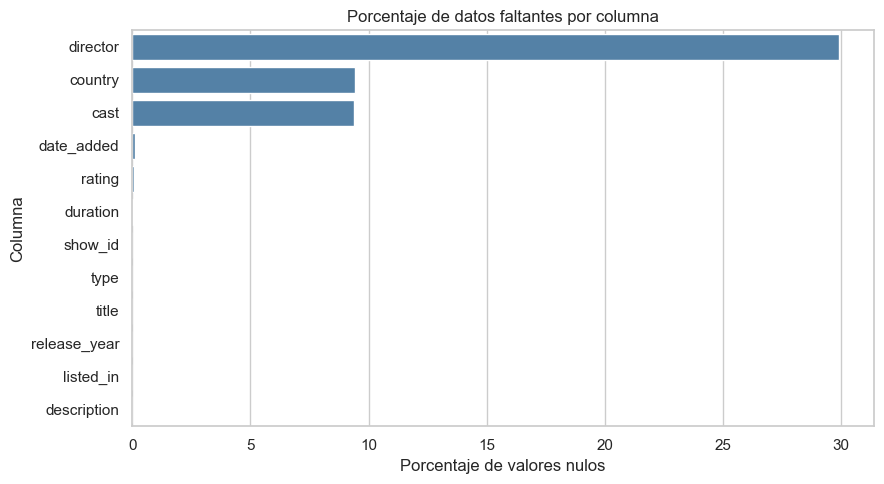

In [34]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2)
}).sort_values("porcentaje_nulos", ascending=False)
display(calidad)
print("Filas completamente duplicadas:", df.duplicated().sum())
print("Identificadores show_id duplicados:", df["show_id"].duplicated().sum())

sns.barplot(data=calidad.reset_index(), x="porcentaje_nulos", y="index", color="steelblue")
plt.title("Porcentaje de datos faltantes por columna")
plt.xlabel("Porcentaje de valores nulos")
plt.ylabel("Columna")
plt.tight_layout()
plt.show()

**Decisión didáctica:** creamos una copia `trabajo` y conservamos `df` intacto. No eliminamos filas por valores faltantes en `director` o `cast`, pues podrían seguir siendo útiles para analizar `type` o `release_year`.

In [35]:
trabajo = df.copy()
trabajo["date_added_dt"] = pd.to_datetime(trabajo["date_added"].str.strip(), errors="coerce")
trabajo["year_added"] = trabajo["date_added_dt"].dt.year
print("Fechas válidas de incorporación:", trabajo["date_added_dt"].notna().sum())

Fechas válidas de incorporación: 8797


### 📝 Preguntas de interpretación
1. ¿Qué columna tiene más datos faltantes? Indica porcentaje.
2. ¿Hay filas o identificadores duplicados?
3. ¿Eliminarías todas las filas con algún nulo? ¿Por qué?
4. ¿Qué significa `errors="coerce"` al convertir fechas?

**Respuestas del estudiante:**

1. La columna con más datos faltantes es director, con 2,634 valores nulos, lo que equivale al 29.91% del total de registros.

2. No, ya que existen 0 filas completamente duplicadas y 0 identificadores duplicados en el conjunto de datos.

3. No ya que si eliminaramos todas las filas con al menos un valor nulo descartaríamos demas informacion valida para analizar otras variables importantes como type, release_year, rating o listed_in.

4. Significa que si una celda contiene un valor con un formato no válido o que no se puede interpretar como fecha, la función convertirá ese valor erróneo en un valor nulo en lugar de detener la ejecución del programa con un error.   

# Parte 4. Clasificación de variables — 4 puntos (10 min)
**Objetivo:** distinguir identificadores, variables categóricas, numéricas, texto y fechas.

**Conceptos:** `release_year` es numérica discreta; `type` es categórica nominal; `show_id` es un identificador, aunque contenga números; `duration` combina número y unidad (minutos o temporadas), por lo que necesita transformación.

In [36]:
clasificacion = pd.DataFrame({
    "Variable": ["show_id", "type", "title", "director", "country", "date_added", "release_year", "rating", "duration", "listed_in"],
    "Tipo de variable": ["Identificador", "Categórica nominal", "Texto", "Texto/categórica", "Texto multivalor", "Fecha (originalmente texto)", "Numérica discreta", "Categórica ordinal aproximada", "Texto mixto", "Texto multivalor"],
    "Utilidad": ["Distinguir registros", "Comparar formatos", "Identificar contenido", "Explorar realizadores", "Explorar procedencia", "Analizar incorporación", "Analizar año de estreno", "Revisar clasificación", "Estudiar duración", "Explorar géneros"]
})
display(clasificacion)

,Variable,Tipo de variable,Utilidad
0,show_id,Identificador,Distinguir registros
1,type,Categórica nominal,Comparar formatos
2,title,Texto,Identificar contenido
3,director,Texto/categórica,Explorar realizadores
4,country,Texto multivalor,Explorar procedencia
5,date_added,Fecha (originalmente texto),Analizar incorporación
6,release_year,Numérica discreta,Analizar año de estreno
7,rating,Categórica ordinal aproximada,Revisar clasificación
8,duration,Texto mixto,Estudiar duración
9,listed_in,Texto multivalor,Explorar géneros


### 📝 Preguntas de interpretación
1. ¿Por qué `show_id` no debe tratarse como una medida numérica?
2. ¿Por qué `duration` requiere limpieza antes de calcular promedios?
3. ¿Qué tipo de variable es `type`?

**Respuestas del estudiante:**

1. Porque a pesar de que está compuesto por números (o letras combinadas con números, como s1, s2), cumple la función de un identificador único. No representa una cantidad, magnitud o medida sobre la cual tenga sentido realizar operaciones aritméticas (como sumar, promediar o calcular desviaciones).

2. Porque es una variable de texto mixto que combina números y unidades en formatos diferentes según el tipo de contenido (por ejemplo, "90 min" para películas y "3 Seasons" para series). Python no puede operar directamente con cadenas de texto combinadas con letras, por lo que es necesario extraer los valores numéricos y separar las unidades antes de calcular cualquier promedio.

3. Es una variable categórica nominal, ya que divide las observaciones en categorías discretas sin un orden o jerarquía natural entre ellas (en este caso, Movie o TV Show).

# Parte 5. Variable categórica `type` — 4 puntos (15 min)
**Objetivo:** comparar películas y series.

**Funciones:** `value_counts()` cuenta categorías; `normalize=True` calcula proporciones; `countplot()` grafica frecuencias. El porcentaje se refiere a **registros del dataset**, no a espectadores ni visualizaciones.

,cantidad,porcentaje
type,,
Movie,6131,69.62
TV Show,2676,30.38


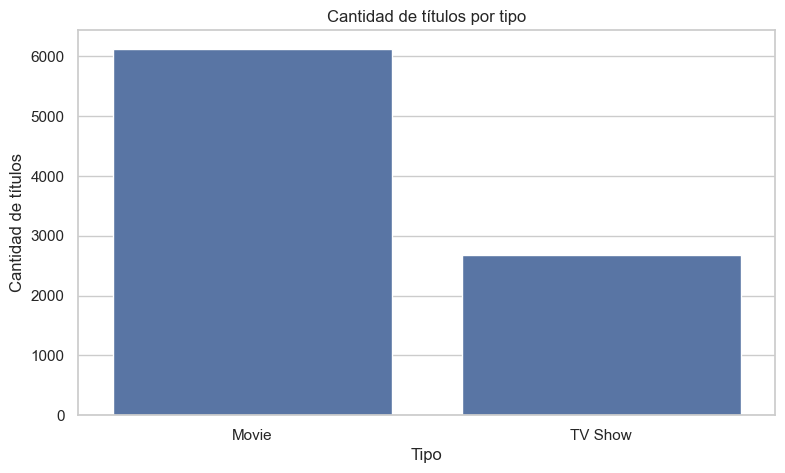

Clasificaciones más frecuentes:


rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64

In [37]:
conteo_tipo = trabajo["type"].value_counts(dropna=False)
porcentaje_tipo = (trabajo["type"].value_counts(normalize=True, dropna=False) * 100).round(2)
display(pd.DataFrame({"cantidad": conteo_tipo, "porcentaje": porcentaje_tipo}))
sns.countplot(data=trabajo, x="type", order=trabajo["type"].value_counts().index)
plt.title("Cantidad de títulos por tipo")
plt.xlabel("Tipo")
plt.ylabel("Cantidad de títulos")
plt.show()

print("Clasificaciones más frecuentes:")
display(trabajo["rating"].value_counts(dropna=False).head(10))

### 📝 Preguntas de interpretación
1. ¿Predominan las películas o las series? Incluye cifras.
2. ¿Cuál es la diferencia entre cantidad y porcentaje?
3. ¿Qué interpretación empresarial podrías proponer sin confundir oferta con consumo?

**Respuestas del estudiante:**

1. Predominan las películas. El catálogo cuenta con 6,131 películas frente a 2,676 series de televisión (TV Shows).

2. La cantidad expresa el número absoluto de registros dentro de una categoría (por ejemplo, 6,131 películas), mientras que el porcentaje representa la proporción relativa de esa categoría respecto al total del conjunto de datos (por ejemplo, las películas representan el 69.62% del total de títulos).

3. Se puede interpretar que la estrategia histórica de adquisición y producción del catálogo ha estado enfocada fuertemente en diversificar y priorizar formatos de larga duración cinematográfica frente a producciones seriadas. Sin embargo, esto refleja únicamente la disponibilidad de títulos en la oferta del catálogo, y no mide el consumo real, la visualización por parte de los usuarios ni la preferencia de los espectadores en la plataforma.

# Parte 6. Variables numéricas y fechas — 4 puntos (15 min)
**Objetivo:** estudiar años de estreno, incorporación y duración de películas.

**Funciones:** `histplot()` muestra distribuciones; `median()` calcula mediana; `to_numeric(errors='coerce')` convierte números; `str.extract()` extrae patrones. **Importante:** no mezclar minutos de películas con temporadas de series.

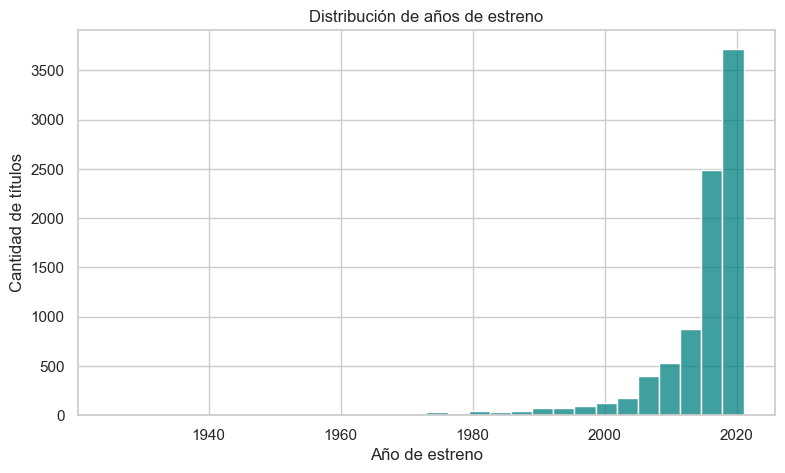

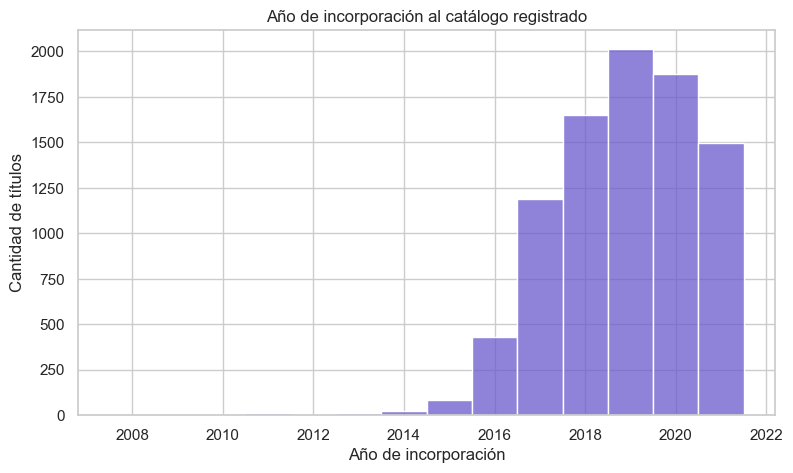

Duraciones válidas (películas): 6128


count       6128.0
mean     99.577187
std      28.290593
min            3.0
25%           87.0
50%           98.0
75%          114.0
max          312.0
Name: minutos, dtype: Float64

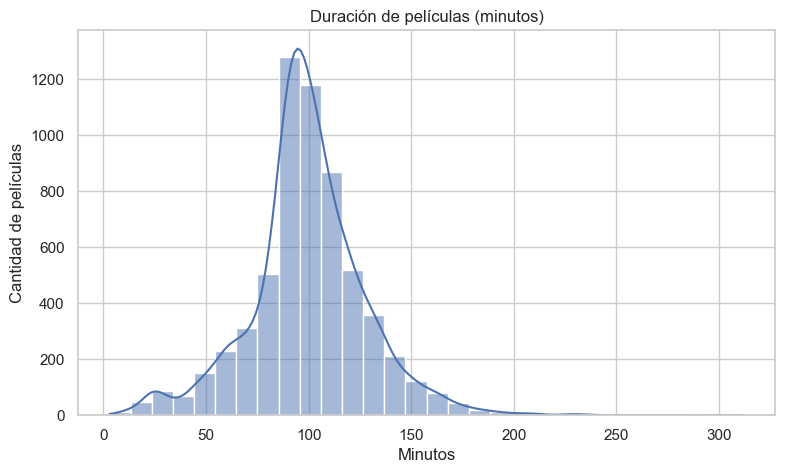

In [38]:
sns.histplot(data=trabajo, x="release_year", bins=30, color="teal")
plt.title("Distribución de años de estreno")
plt.xlabel("Año de estreno")
plt.ylabel("Cantidad de títulos")
plt.show()

sns.histplot(data=trabajo.dropna(subset=["year_added"]), x="year_added", discrete=True, color="slateblue")
plt.title("Año de incorporación al catálogo registrado")
plt.xlabel("Año de incorporación")
plt.ylabel("Cantidad de títulos")
plt.show()

peliculas = trabajo.loc[trabajo["type"].eq("Movie")].copy()
peliculas["minutos"] = pd.to_numeric(
    peliculas["duration"].astype("string").str.extract(r"^(\d+)\s+min$", expand=False), errors="coerce"
)
print("Duraciones válidas (películas):", peliculas["minutos"].notna().sum())
display(peliculas["minutos"].describe())
sns.histplot(data=peliculas.dropna(subset=["minutos"]), x="minutos", bins=30, kde=True)
plt.title("Duración de películas (minutos)")
plt.xlabel("Minutos")
plt.ylabel("Cantidad de películas")
plt.show()

### 📝 Preguntas de interpretación
1. ¿En qué periodo se concentran los años de estreno?
2. ¿Por qué año de estreno y año de incorporación no son equivalentes?
3. ¿Cuál es la duración mediana de las películas con dato válido?
4. ¿Por qué excluimos series del histograma de minutos?

**Respuestas del estudiante:**

1. Los años de estreno se concentran fuertemente en el periodo más reciente del catálogo, una gran cantidad con respecto al estreno de titulos fueron aumentando desde el año 2015 en adelante.

2. Porque el año de estreno indica cuando se produjo originalmente la obra al mercado, mientras que el año de incorporación indica el momento en el que Netflix adquirió dicho contenido a su plataforma digital.

3. La duración mediana de las películas con datos válidos es de 98 minutos, con una media aproximada de 99.58 minutos.

4. Porque las series miden su duracion en temporadas y no en minutos individuales por episodio.

# Parte 7. Detección de posibles valores atípicos — 3 puntos (10 min)
**Objetivo:** observar duraciones inusuales sin eliminarlas automáticamente.

**Funciones:** `boxplot()` muestra mediana, cuartiles y puntos fuera de los bigotes. La regla IQR es un criterio estadístico, **no una prueba de error**.

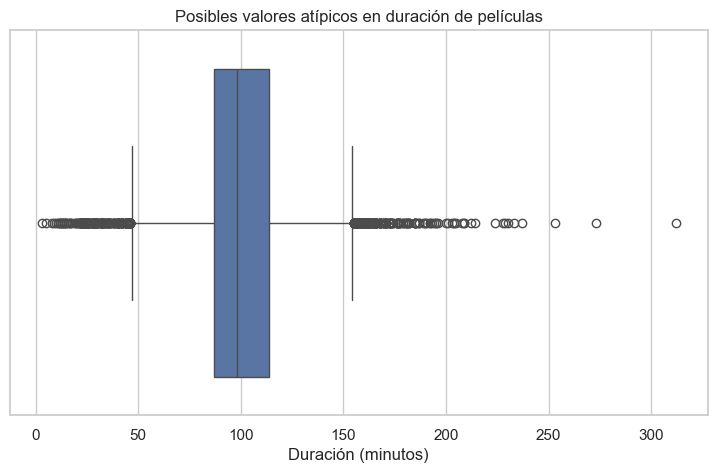

Límites IQR: 46.5 a 154.5 minutos
Posibles atípicos: 450


,title,minutos
4253,Black Mirror: Bandersnatch,312
717,Headspace: Unwind Your Mind,273
2491,The School of Mischief,253
2487,No Longer kids,237
2484,Lock Your Girls In,233
2488,Raya and Sakina,230
166,Once Upon a Time in America,229
7932,Sangam,228
1019,Lagaan,224
4573,Jodhaa Akbar,214


In [39]:
duraciones = peliculas["minutos"].dropna()
if duraciones.empty:
    print("No hay duraciones numéricas válidas para dibujar el boxplot.")
else:
    sns.boxplot(x=duraciones)
    plt.title("Posibles valores atípicos en duración de películas")
    plt.xlabel("Duración (minutos)")
    plt.show()
    q1, q3 = duraciones.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5*iqr, q3 + 1.5*iqr
    extremos = peliculas.loc[(peliculas["minutos"] < limite_inferior) | (peliculas["minutos"] > limite_superior), ["title", "minutos"]]
    print(f"Límites IQR: {limite_inferior:.1f} a {limite_superior:.1f} minutos")
    print("Posibles atípicos:", len(extremos))
    display(extremos.sort_values("minutos", ascending=False).head(10))

### 📝 Preguntas de interpretación
1. ¿Qué películas aparecen con duraciones especialmente altas o bajas?
2. ¿Eliminarías automáticamente esos registros? Justifica.
3. ¿Qué verificación harías antes de corregir una duración?

**Respuestas del estudiante:**

1. Duraciones especialmente altas superiores al límite superior de 154.5 minutos: Aparecen producciones de larga duración, documentales interactivos o películas especiales como Black Mirror: Bandersnatch (312 minutos) o Headspace: Unwind Your Mind (273 minutos).\
    Duraciones especialmente bajas (inferiores al límite inferior de 46.5 minutos): Aparecen cortometrajes, especiales experimentales o piezas de contenido breve como Silent (3 minutos) o Sol Levante (5 minutos).

2. No. Un valor atípico determinado por la regla del rango intercuartil (IQR) es únicamente una señal estadística de que el dato se aleja de la tendencia central, pero no implica que sea un error. En catálogos de streaming es completamente normal encontrar cortometrajes experimentales o películas excepcionalmente largas como películas épicas, miniseries documentales o especiales interactivos. Eliminarlos sesgaría la realidad del catálogo.

3. Se debería consultar la fuente oficial o una base de datos externa de referencia para comprobar si el dato original en el dataset corresponde a un error tipográfico de captura (por ejemplo, que a una serie se le haya asignado erróneamente el formato de película) o si, por el contrario, la duración inusual es totalmente verídica y correcta.

# Parte 8. Relación entre variables — 3 puntos (10 min)
**Objetivo:** comparar el tipo de contenido a través de los años y observar diferencias entre grupos.

**Funciones:** `crosstab()` cuenta combinaciones; `groupby()` agrupa registros; `lineplot()` permite observar evolución. Este gráfico describe el **catálogo registrado**, no la popularidad.

type,Movie,TV Show
year_added,,
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,5
2014.0,19,5
2015.0,56,26
2016.0,253,176
2017.0,839,349
2018.0,1237,412


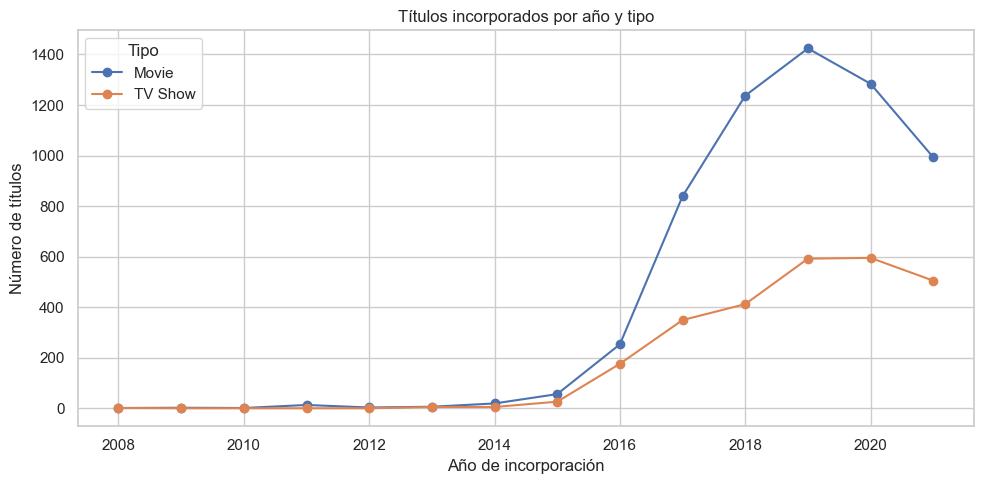

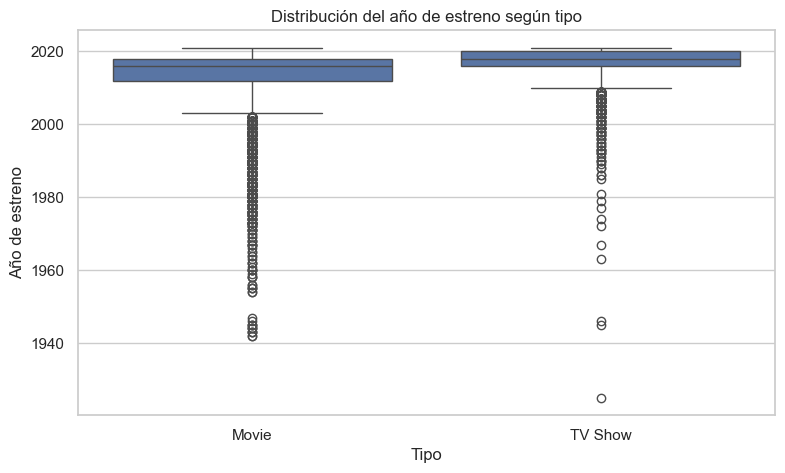

In [40]:
tabla = pd.crosstab(trabajo["year_added"], trabajo["type"])
display(tabla.tail(12))
if not tabla.empty:
    tabla.plot(kind="line", marker="o", figsize=(10,5))
    plt.title("Títulos incorporados por año y tipo")
    plt.xlabel("Año de incorporación")
    plt.ylabel("Número de títulos")
    plt.legend(title="Tipo")
    plt.tight_layout()
    plt.show()

# Otra comparación: año de estreno por tipo
sns.boxplot(data=trabajo, x="type", y="release_year")
plt.title("Distribución del año de estreno según tipo")
plt.xlabel("Tipo")
plt.ylabel("Año de estreno")
plt.show()

### 📝 Preguntas de interpretación
1. ¿Qué diferencias observas entre películas y series por año de incorporación?
2. ¿Puedes concluir que un formato fue más visto? Explica.
3. ¿Qué otra variable cruzarías con `type` para investigar el catálogo?

**Respuestas del estudiante:**

1. Se observa que ambos formatos muestran un crecimiento exponencial en la cantidad de títulos añadidos a partir de los años 2016-2018, pero las películas siempre superan ampliamente en volumen absoluto a las series de televisión en cada uno de los años registrados, manteniendo una brecha constante en la velocidad de incorporación de nuevos contenidos al catálogo.

2. No. Este conjunto de datos refleja exclusivamente la oferta de títulos disponibles en el catálogo histórico de la plataforma, pero no contiene métricas de visualización, reproducciones ni tiempo de consumo real por parte de los usuarios. Por lo tanto, un mayor número de películas en el catálogo no demuestra necesariamente que hayan sido más vistas que las series.

3. Se podría cruzar con la variable rating para analizar cómo se distribuyen las clasificaciones por edades entre películas y series o con release_year para evaluar si las series añadidas suelen ser de producciones más recientes en comparación con las películas incorporadas.

# Parte 9. Matriz de correlación — 2 puntos (10 min)
**Objetivo:** analizar relación lineal entre dos medidas numéricas: año de estreno y duración de películas.

**Funciones:** `corr()` calcula correlación de Pearson; `heatmap()` la representa. Valores cercanos a +1/-1 indican asociación lineal positiva/negativa; cerca de 0, asociación lineal débil. **Correlación no implica causalidad.** No se incluyen identificadores ni categorías convertidas artificialmente a números.

,release_year,minutos
release_year,1.000000,-0.206285
minutos,-0.206285,1.000000


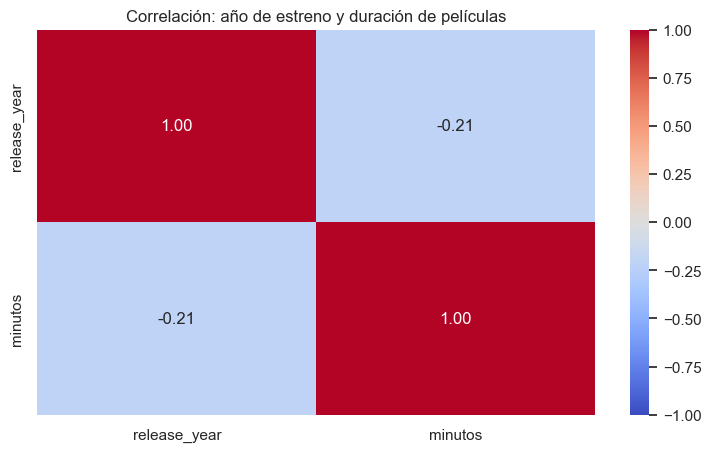

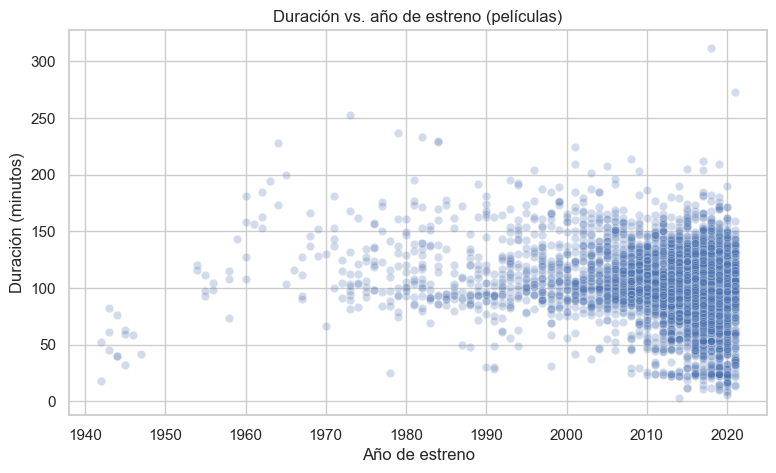

In [41]:
variables_corr = peliculas[["release_year", "minutos"]].dropna()
if len(variables_corr) >= 3 and variables_corr.nunique().min() > 1:
    matriz = variables_corr.corr(numeric_only=True)
    display(matriz)
    sns.heatmap(matriz, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
    plt.title("Correlación: año de estreno y duración de películas")
    plt.show()
    sns.scatterplot(data=variables_corr, x="release_year", y="minutos", alpha=0.25)
    plt.title("Duración vs. año de estreno (películas)")
    plt.xlabel("Año de estreno")
    plt.ylabel("Duración (minutos)")
    plt.show()
else:
    print("No hay suficientes valores numéricos variables para una correlación interpretable.")

### 📝 Preguntas de interpretación
1. ¿Qué valor de correlación obtuviste y cómo lo interpretas?
2. ¿Por qué no incluimos `show_id`, `title` o `type` en la matriz?
3. ¿Puede afirmarse causalidad a partir de este resultado?

**Respuestas del estudiante:**

1. Se obtiene un coeficiente de correlación de Pearson de aproximadamente -0.21 entre el año de estreno y la duración de las películas. Esto indica una asociación lineal negativa débil: las películas más recientes tienden a ser ligeramente más cortas en promedio que las producciones de años anteriores, aunque la dispersión es amplia y la relación lineal no es fuerte.

2. Porque la matriz de correlación numérica requiere variables cuantitativas continuas o discretas sobre las cuales tenga sentido matemático calcular la covarianza lineal. show_id y title son identificadores y textos únicos sin significado numérico, y type es una variable categórica nominal.

3. No. Como se destaca en el análisis exploratorio, la correlación estadística entre dos variables nunca implica causalidad. Que exista una leve tendencia negativa no significa que el año de estreno cause directamente que una película dure menos minutos; podría deberse a cambios generales en las tendencias de la industria, formatos de distribución o preferencias comerciales a lo largo del tiempo.

# Parte 10. Conclusión general — 3 puntos (10 min)
**Entrega:** redacta una conclusión de **8 a 12 líneas** que incluya: (1) qué contiene la base; (2) dos hallazgos con números; (3) calidad de datos y límites; (4) una recomendación razonable; (5) una pregunta para investigar después.

**Conclusión del estudiante:**

El conjunto de datos analizado contiene una instantánea histórica del catálogo de contenidos de Netflix, abarcando un total de 8,807 registros entre películas y series de televisión. Entre los principales hallazgos numéricos, destaca que las películas predominan en la oferta con 6,131 registros (69.62%), frente a las 2,676 series (TV Shows), y que la duración mediana de las películas se sitúa en 98 minutos. Respecto a la calidad de los datos, se identificaron valores faltantes significativos, especialmente en la columna director (29.91%), decidiendo conservar las filas para evitar la pérdida masiva de información útil. Como limitación principal, la base refleja únicamente la disponibilidad histórica del catálogo y no representa métricas de consumo o visualización real. Se recomienda utilizar datos de reproducciones de los usuarios para respaldar futuras decisiones de producción y adquisición de contenidos. Como interrogante para investigar después, cabe preguntarse: ¿Cómo varían las preferencias de visualización por género según la región geográfica?

**Reflexión final:** ¿Qué aporta el EDA antes de entrenar un modelo de inteligencia artificial?

El Análisis Exploratorio de Datos (EDA) es fundamental antes de entrenar un modelo de inteligencia artificial porque permite comprender a fondo la estructura de la información, detectar problemas de calidad (como valores nulos, duplicados o inconsistencias) y reconocer la presencia de valores atípicos que podrían sesgar el aprendizaje del algoritmo. Asimismo, facilita la selección adecuada de las variables predictoras, revela relaciones lineales o patrones ocultos y orienta las transformaciones necesarias para garantizar que el modelo se alimente de datos limpios, fiables y estadísticamente sólidos.

# 🎤 Bloque B — Exposición y defensa oral (60 minutos · 15 puntos)

## Guion de presentación (5 minutos por equipo)
1. **Pregunta de investigación (30 s):** ¿qué queríamos descubrir?
2. **Datos y calidad (60 s):** tamaño de la base, variables relevantes y un problema de calidad detectado.
3. **Dos visualizaciones (2 min):** mostrar cada gráfico, explicar los ejes y qué revelan.
4. **Tres hallazgos (1 min):** usar cifras verificables.
5. **Limitación y recomendación (30 s):** qué no puede concluirse con esta base.

## Banco de preguntas del docente (3 minutos por equipo; seleccionar 2 o 3)
1. ¿Qué representa exactamente una fila de este dataset?
2. ¿Cuál fue la columna con más valores faltantes y cómo afecta al análisis?
3. ¿Por qué no sería correcto eliminar automáticamente todas las filas incompletas?
4. ¿Qué diferencia existe entre `value_counts()` y `groupby()`?
5. ¿Qué muestran los ejes del gráfico que eligieron?
6. ¿Qué cambia al comparar cantidades absolutas frente a porcentajes?
7. ¿Qué significa un valor atípico en la duración de una película? ¿Es necesariamente un error?
8. ¿Cuál es la diferencia entre `release_year` y el año de `date_added`?
9. ¿Una correlación alta demuestra causalidad? ¿Por qué?
10. ¿Podemos afirmar que el género más frecuente es el más visto? Justifiquen.
11. ¿Qué sesgos o limitaciones tiene una instantánea histórica del catálogo?
12. Si fueran analistas de Netflix, ¿qué información adicional solicitarían para decidir qué contenido producir?

## Espacio para preparar respuestas
**Gráfico 1 seleccionado:** Gráfico de barras de títulos por tipo

**¿Qué demuestra?** Muestra la distribución del catálogo según el formato, demostrando una marcada preferencia de la plataforma por la oferta de películas respecto a las series de televisión.

**Gráfico 2 seleccionado:** Gráfico de líneas de títulos incorporados por año y tipo.

**¿Qué demuestra?** Muestra la evolución temporal de las adiciones al catálogo, evidenciando un pico masivo de incorporación de contenidos a partir de 2015 y consolidado por el año 2020.

**Hallazgo 1 (con cifra):** El catálogo está compuesto predominantemente por películas, las cuales representan el 69.62% (6,131 títulos) frente al 30.38% de series de televisión (2,676 títulos).

**Hallazgo 2 (con cifra):** La duración mediana de las películas en el catálogo es de 98 minutos, ubicándose el 50% de ellas en un rango entre 87 y 114 minutos.

**Hallazgo 3 (con cifra):** La columna director presenta el mayor porcentaje de datos faltantes en la base, con un 29.91% de registros nulos (2,634 títulos sin director especificado).

**Limitación importante:** El dataset es una instantánea histórica que describe únicamente la oferta disponible en el catálogo; no incluye métricas de consumo real, reproducciones, calificaciones del público ni horas vistas por los usuarios.

**Recomendación:** Complementar el análisis del catálogo con datos internos de visualización y retención de usuarios para fundamentar futuras decisiones de adquisición y producción original de contenidos.


# 📋 Rúbrica de evaluación — 50 puntos

### A. Taller práctico (35 puntos)
| Parte | Criterio | Puntos |
|---|---|---:|
| 1 | Carga correcta y comprensión de fuente | 3 |
| 2 | Exploración inicial e interpretación | 5 |
| 3 | Calidad de datos y decisiones justificadas | 4 |
| 4 | Identificación de tipos de variables | 4 |
| 5 | Frecuencias y gráfico categórico | 4 |
| 6 | Gráficos de años, fechas y duración | 4 |
| 7 | Boxplot e interpretación de atípicos | 3 |
| 8 | Cruces y comparación de variables | 3 |
| 9 | Correlación y cautela causal | 2 |
| 10 | Conclusiones con evidencia | 3 |
| | **Subtotal** | **35** |

### B. Exposición y defensa (15 puntos)
| Criterio | Puntos | Evidencia |
|---|---:|---|
| Explicación clara del problema y dataset | 3 | Describe qué contiene y qué no contiene |
| Presentación e interpretación de 2 gráficos | 4 | Explica ejes, frecuencias y hallazgos |
| Tres conclusiones fundamentadas | 3 | Utiliza resultados del notebook |
| Respuestas a preguntas del docente | 4 | Argumenta, reconoce límites y errores |
| Participación y organización del equipo | 1 | Intervención equilibrada y tiempo |
| **Subtotal** | **15** | |
| **TOTAL** | **50** | |

**Importante:** la calificación valora la interpretación, no solo la ejecución del código. El docente puede hacer preguntas individuales dentro de la defensa del equipo.